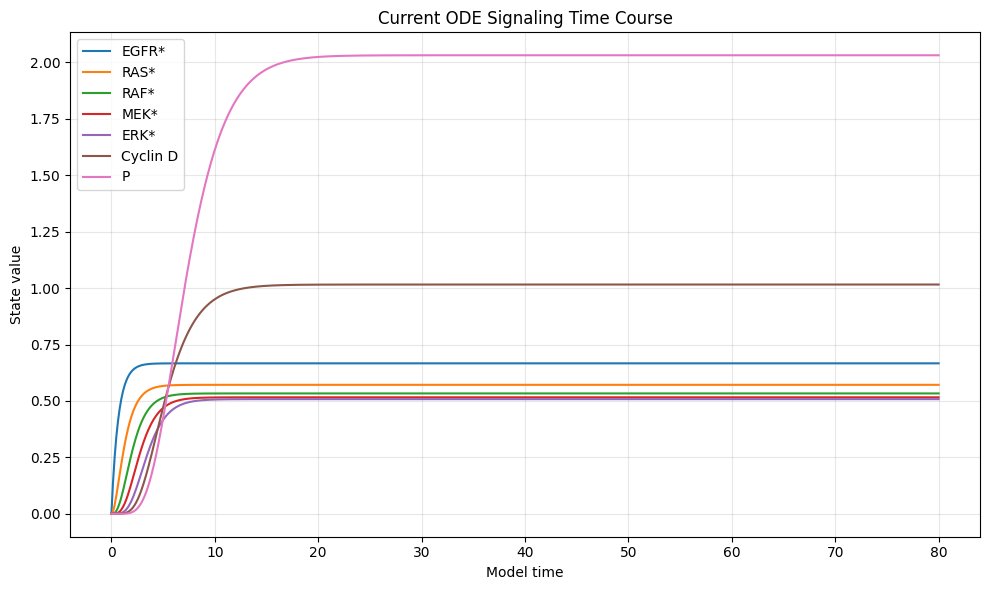

In [28]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# --------------------------------------------------
# ODE TIME-COURSE DIAGNOSTIC
# Uses the CURRENT model parameters without fitting
# --------------------------------------------------

# y : [EGFR, RAS, RAF, MEK, ERK, CycD, P]
def pathway(t, y, params):
    # External factors
    EGF = params["EGF"]
    G = params["G"]
    IC_50 = params["IC_50"]
    n = params["n"]

    # Extract activated protein and Cyclin D/Proliferation rates from array y
    EGFR_star, RAS_star, RAF_star, MEK_star, ERK_star, CycD, P = y

    # Total protein concentrations
    EGFR_tot = 1.0
    RAS_tot = 1.0
    RAF_tot = 1.0
    MEK_tot = 1.0
    ERK_tot = 1.0

    # Rate constants (normalized currently)
    k_EGF = params["k_EGF"]
    k_EGFR_off = params["k_EGFR_off"]

    k_RAS = params["k_RAS"]
    k_RAS_off = params["k_RAS_off"]

    k_RAF = params["k_RAF"]
    k_RAF_off = params["k_RAF_off"]

    k_MEK = params["k_MEK"]
    k_MEK_off = params["k_MEK_off"]

    k_ERK = params["k_ERK"]
    k_ERK_off = params["k_ERK_off"]

    k_T = params["k_T"]
    k_deg = params["k_deg"]

    k_P = params["k_P"]
    k_loss = params["k_loss"]

    # Calculating derivatives
    EGFR_gefit = 1 / (1 + (G / IC_50) ** n)
    EGFR_act = k_EGF * EGF * (EGFR_tot - EGFR_star) * EGFR_gefit
    EGFR_dect = k_EGFR_off * EGFR_star

    dEGFR = EGFR_act - EGFR_dect

    RAS_act = k_RAS * EGFR_star * (RAS_tot - RAS_star)
    RAS_dect = k_RAS_off * RAS_star

    dRAS = RAS_act - RAS_dect

    RAF_act = k_RAF * RAS_star * (RAF_tot - RAF_star)
    RAF_dect = k_RAF_off * RAF_star

    dRAF = RAF_act - RAF_dect

    MEK_act = k_MEK * RAF_star * (MEK_tot - MEK_star)
    MEK_dect = k_MEK_off * MEK_star

    dMEK = MEK_act - MEK_dect

    ERK_act = k_ERK * MEK_star * (ERK_tot - ERK_star)
    ERK_dect = k_ERK_off * ERK_star

    dERK = ERK_act - ERK_dect

    CycD_act = k_T * ERK_star
    CycD_dect = k_deg * CycD

    dCycD = CycD_act - CycD_dect

    P_act = k_P * CycD
    P_dect = k_loss * P

    dP = P_act - P_dect

    return [dEGFR, dRAS, dRAF, 
                dMEK, dERK, dCycD, dP]

# External parameter value dictionary
params = {
    "EGF" : 1.0,
    "G" : 0.0,
    "IC_50" : 0.3,
    "n" : 1.0,
    "k_EGF" : 1.0,
    "k_EGFR_off" : 0.5,
    "k_RAS" : 1.0,
    "k_RAS_off" : 0.5,
    "k_RAF" : 1.0,
    "k_RAF_off" : 0.5,
    "k_MEK" : 1.0,
    "k_MEK_off" : 0.5,
    "k_ERK" : 1.0,
    "k_ERK_off" : 0.5,
    "k_T" : 1.0,
    "k_deg" : 0.5,
    "k_P" : 1.0,
    "k_loss" : 0.5,
}

# Initial conditions
y0 = np.zeros(7)

# Model time range
T_timecourse = 80
t_eval = np.linspace(0, T_timecourse, 1000)

# Use a uniform drug concentration for this diagnostic
# so we're examining the intrinsic signaling dynamics,
# not spatial diffusion.
G_test = 0.0

# Solve ODE
solution = solve_ivp(
    pathway,
    [0, T_timecourse],
    y0,
    args=(params,),
    t_eval=t_eval,
    rtol=1e-9,
    atol=1e-12
)

if not solution.success:
    raise RuntimeError(solution.message)

# Species names
species_names = [
    "EGFR*",
    "RAS*",
    "RAF*",
    "MEK*",
    "ERK*",
    "Cyclin D",
    "P"
]

# --------------------------------------------------
# Plot all trajectories
# --------------------------------------------------

plt.figure(figsize=(10, 6))

for i, name in enumerate(species_names):
    plt.plot(solution.t, solution.y[i], label=name)

plt.xlabel("Model time")
plt.ylabel("State value")
plt.title("Current ODE Signaling Time Course")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# import numpy as np
# import matplotlib.pyplot as plt
# from scipy.integrate import solve_ivp
# from scipy.optimize import minimize_scalar

# # ============================================================
# # 1. DIGITIZED EXPERIMENTAL DATA
# #    H1975 + 100 ng/mL EGF
# #    Approximate values digitized from the published figure
# # ============================================================

# exp_time = np.array([
#     0, 1, 3, 5, 10, 15, 30, 60
# ])

# exp_Y1068 = np.array([
#     180, 155, 150, 145, 145, 145, 140, 138
# ])

# exp_Y1148 = np.array([
#     125, 105, 115, 120, 120, 105, 115, 120
# ])

# exp_Y1173 = np.array([
#     125, 125, 130, 135, 140, 125, 65, 65
# ])

# experimental = {
#     "Y1068": exp_Y1068,
#     "Y1148": exp_Y1148,
#     "Y1173": exp_Y1173
# }


# # ============================================================
# # 2. RUN YOUR CURRENT MODEL
# # ============================================================

# # Use your existing params, y0, pathway(), and T_steady.
# # We use G = 0 because this is the no-drug / EGF-stimulation
# # condition.

# model_time = np.linspace(0, T_timecourse, 1000)

# params_1 = params.copy()

# params_1["G"] = 0.0

# solution = solve_ivp(
#     pathway,
#     [0, T_timecourse],
#     y0,
#     args=(params_1),
#     t_eval=model_time,
#     rtol=1e-9,
#     atol=1e-12
# )

# if not solution.success:
#     raise RuntimeError(solution.message)

# EGFR_model = solution.y[0]


# # ============================================================
# # 3. NORMALIZE MODEL
# # ============================================================

# # Current model starts at 0 and approaches a steady state.
# model_initial = EGFR_model[0]
# model_final = EGFR_model[-1]

# EGFR_model_norm = (
#     EGFR_model - model_initial
# ) / (
#     model_final - model_initial
# )


# # ============================================================
# # 4. NORMALIZE EXPERIMENTAL DATA
# # ============================================================

# def normalize_experiment(y):
#     """
#     Normalize relative intensity so that:
#         first point = 0
#         maximum = 1

#     This is intentional: we're testing activation TIMESCALE,
#     not absolute phosphosite intensity.
#     """
    
#     y0_exp = y[0]
#     ymax_exp = np.max(y)

#     return (y - y0_exp) / (ymax_exp - y0_exp)


# experimental_norm = {
#     name: normalize_experiment(values)
#     for name, values in experimental.items()
# }


# # ============================================================
# # 5. FIT ONE GLOBAL TIME-SCALING FACTOR
# # ============================================================

# # Our model time units are arbitrary.
# #
# # Let:
# #
# #       experimental_minutes = scale * model_time
# #
# # We fit ONE scale for all three phosphosites.
# #
# # IMPORTANT:
# # Only use the first 10 minutes here because the current
# # model is monotonic and cannot reproduce the later transient
# # decline in Y1068/Y1173.

# activation_mask = exp_time <= 10
# fit_times = exp_time[activation_mask]


# def model_at_experimental_times(scale):
#     """
#     Convert experimental minutes into model time and
#     interpolate the model trajectory.
#     """

#     model_times_needed = fit_times / scale

#     return np.interp(
#         model_times_needed,
#         model_time,
#         EGFR_model_norm
#     )


# def objective(log_scale):
#     """
#     Optimize log(scale) so that scale stays positive.
#     """

#     scale = np.exp(log_scale)

#     model_values = model_at_experimental_times(scale)

#     error = 0

#     for name in experimental_norm:
#         exp_values = experimental_norm[name][activation_mask]

#         error += np.sum(
#             (model_values - exp_values) ** 2
#         )

#     return error


# result = minimize_scalar(
#     objective,
#     bounds=(np.log(0.01), np.log(1000)),
#     method="bounded"
# )

# if not result.success:
#     raise RuntimeError("Time-scale optimization failed.")

# time_scale = np.exp(result.x)


# print("\n===== TEMPORAL SCALE FIT =====")
# print(f"Best-fit time scale: {time_scale:.3f} min/model time unit")


# # ============================================================
# # 6. CALCULATE MODEL t50 AND t90
# # ============================================================

# def crossing_time(time, response, threshold):
#     """
#     Find the first time the normalized response reaches
#     a specified threshold.
#     """

#     index = np.where(response >= threshold)[0]

#     if len(index) == 0:
#         return np.nan

#     i = index[0]

#     if i == 0:
#         return time[0]

#     # Linear interpolation between neighboring points
#     t1 = time[i - 1]
#     t2 = time[i]

#     y1 = response[i - 1]
#     y2 = response[i]

#     return t1 + (threshold - y1) * (t2 - t1) / (y2 - y1)


# model_t50 = crossing_time(
#     model_time,
#     EGFR_model_norm,
#     0.50
# )

# model_t90 = crossing_time(
#     model_time,
#     EGFR_model_norm,
#     0.90
# )

# print(f"Model t50: {model_t50:.3f} model time units")
# print(f"Model t90: {model_t90:.3f} model time units")

# print(f"Model t50: {model_t50 * time_scale:.3f} min")
# print(f"Model t90: {model_t90 * time_scale:.3f} min")


# # ============================================================
# # 7. PLOT EXPERIMENT VS MODEL
# # ============================================================

# # Convert model time into experimental minutes
# model_time_minutes = model_time * time_scale

# plt.figure(figsize=(9, 6))

# # Model
# plt.plot(
#     model_time_minutes,
#     EGFR_model_norm,
#     linewidth=2.5,
#     label="Current EGFR* model"
# )

# # Experimental curves
# markers = {
#     "Y1068": "o",
#     "Y1148": "s",
#     "Y1173": "^"
# }

# for name, values in experimental_norm.items():

#     plt.scatter(
#         exp_time,
#         values,
#         marker=markers[name],
#         s=55,
#         label=f"H1975 EGFR {name}"
#     )

# # Highlight the region used for fitting
# plt.axvspan(
#     0,
#     10,
#     alpha=0.1,
#     label="Activation phase used for fit"
# )

# plt.xlabel("Time (min)")
# plt.ylabel("Normalized EGFR activation")
# plt.title("EGFR temporal dynamics: model vs H1975 experiment")

# plt.xlim(0, 60)
# plt.ylim(-0.1, 1.15)

# plt.legend()
# plt.grid(alpha=0.25)

# plt.tight_layout()
# plt.show()

TypeError: pathway() takes 3 positional arguments but 20 were given

In [30]:
# --------------------------------------------------
# Inspect intrinsic EGFR* dynamics
# --------------------------------------------------

EGFR_model = solution.y[0]

print("\n===== MODEL DIAGNOSTIC =====")
print(f"Initial EGFR*: {EGFR_model[0]:.6f}")
print(f"Final EGFR*:   {EGFR_model[-1]:.6f}")
print(f"Maximum EGFR*: {np.max(EGFR_model):.6f}")

# Check whether EGFR* is monotonic
EGFR_changes = np.diff(EGFR_model)

print(f"Number of EGFR* decreases: {np.sum(EGFR_changes < 0)}")


===== MODEL DIAGNOSTIC =====
Initial EGFR*: 0.000000
Final EGFR*:   0.666667
Maximum EGFR*: 0.666667
Number of EGFR* decreases: 201


In [31]:
# --------------------------------------------------
# Normalize model EGFR*
# --------------------------------------------------

EGFR_model_norm = (
    EGFR_model - EGFR_model[0]
) / (
    EGFR_model[-1] - EGFR_model[0]
)

In [32]:
# --------------------------------------------------
# Digitized H1975 EGFR phosphosite data
# 100 ng/mL EGF
# Approximate values from published figure
# --------------------------------------------------

exp_time = np.array([
    0, 1, 3, 5, 10, 15, 30, 60
])

exp_Y1068 = np.array([
    180, 155, 150, 145, 145, 145, 140, 138
])

exp_Y1148 = np.array([
    125, 105, 115, 120, 120, 105, 115, 120
])

exp_Y1173 = np.array([
    125, 125, 130, 135, 140, 125, 65, 65
])

experimental = {
    "Y1068": exp_Y1068,
    "Y1148": exp_Y1148,
    "Y1173": exp_Y1173
}

# --------------------------------------------------
# Normalize experimental trajectories
# --------------------------------------------------

def normalize_experiment(y):
    return y / y[0]


experimental_norm = {
    name: normalize_experiment(values)
    for name, values in experimental.items()
}

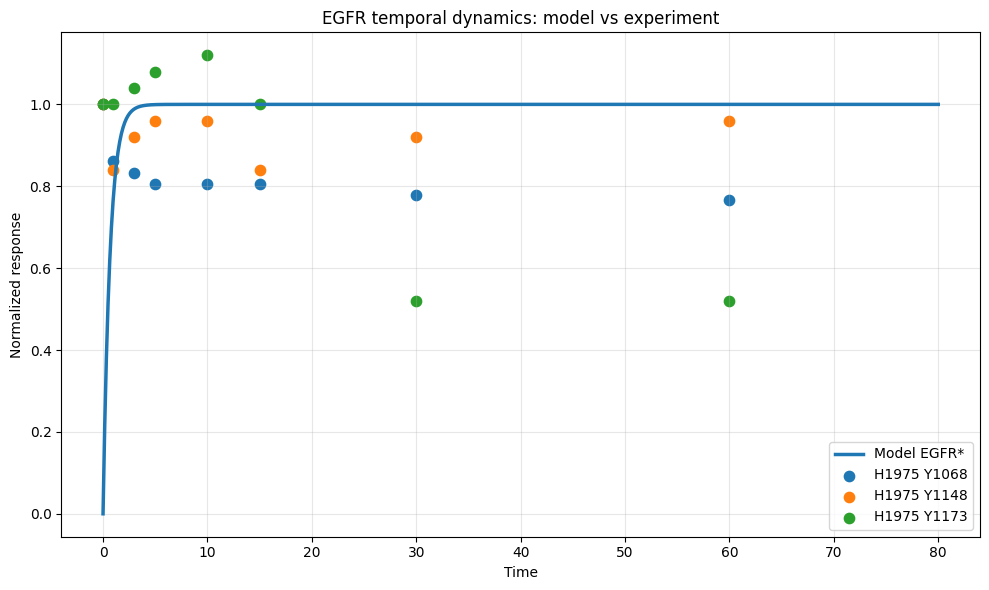

In [33]:
# --------------------------------------------------
# Compare raw temporal shapes
# --------------------------------------------------

plt.figure(figsize=(10, 6))

plt.plot(
    solution.t,
    EGFR_model_norm,
    linewidth=2.5,
    label="Model EGFR*"
)

for name, values in experimental_norm.items():
    plt.scatter(
        exp_time,
        values,
        s=55,
        label=f"H1975 {name}"
    )

plt.xlabel("Time")
plt.ylabel("Normalized response")
plt.title("EGFR temporal dynamics: model vs experiment")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [34]:
# --------------------------------------------------
# Calculate model t50 and t90
# --------------------------------------------------

def crossing_time(time, response, threshold):

    indices = np.where(response >= threshold)[0]

    if len(indices) == 0:
        return np.nan

    i = indices[0]

    if i == 0:
        return time[0]

    t1 = time[i - 1]
    t2 = time[i]

    y1 = response[i - 1]
    y2 = response[i]

    return t1 + (threshold - y1) * (t2 - t1) / (y2 - y1)


model_t50 = crossing_time(
    solution.t,
    EGFR_model_norm,
    0.50
)

model_t90 = crossing_time(
    solution.t,
    EGFR_model_norm,
    0.90
)

print("\n===== MODEL TIMESCALE =====")
print(f"t50 = {model_t50:.3f} model time units")
print(f"t90 = {model_t90:.3f} model time units")


===== MODEL TIMESCALE =====
t50 = 0.463 model time units
t90 = 1.536 model time units


Global time-scale factor: 7.328 min/model time unit
Validation MSE: 0.008313
RMSE: 0.0912
MAE:  0.0674


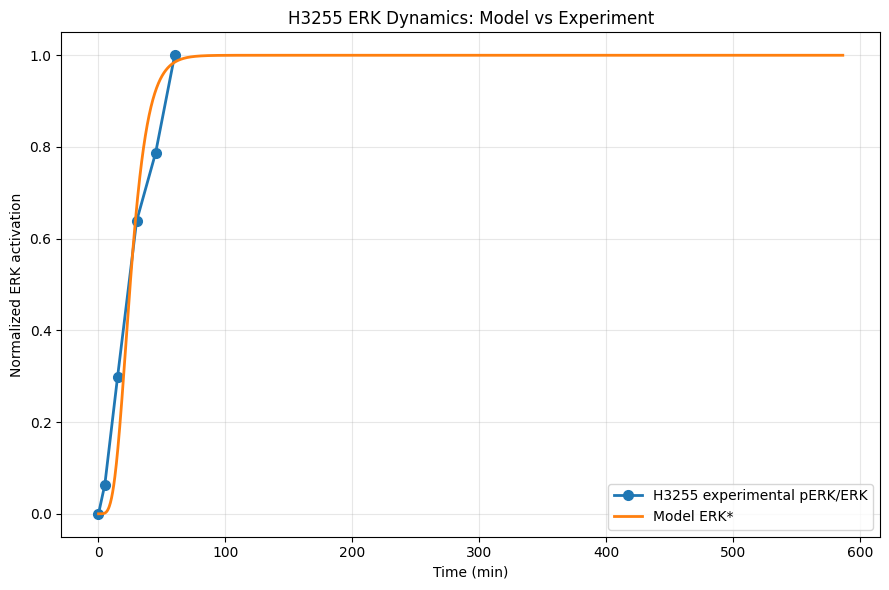


Point-by-point comparison:
Time (min) | Experiment | Model | Difference
         0 |      0.000 | 0.000 | +0.000
         5 |      0.064 | 0.002 | -0.062
        15 |      0.298 | 0.135 | -0.163
        30 |      0.638 | 0.667 | +0.028
        45 |      0.787 | 0.923 | +0.136
        60 |      1.000 | 0.985 | -0.015


In [37]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar

# ============================================================
# 1. Experimental H3255 ERK data from Figure S1
#    Approximate digitization from the plotted points
# ============================================================

exp_time = np.array([0, 5, 15, 30, 45, 60], dtype=float)

exp_pERK = np.array([
    0.08,
    0.11,
    0.22,
    0.38,
    0.45,
    0.55
])

# ============================================================
# 2. Run your EXISTING signaling model
# ============================================================

params["G"] = 0.0

T_timecourse = 80

t_model = np.linspace(0, T_timecourse, 2000)

solution = solve_ivp(
    pathway,
    [0, T_timecourse],
    y0,
    args=(params,),
    t_eval=t_model,
    rtol=1e-9,
    atol=1e-12
)

# ERK* is the 5th state variable
model_ERK = solution.y[4]

# ============================================================
# 3. Normalize both curves to compare SHAPE
# ============================================================

# Experimental fractional increase from baseline
exp_norm = (
    (exp_pERK - exp_pERK[0])
    / (exp_pERK[-1] - exp_pERK[0])
)

# Model fractional increase
model_norm = (
    (model_ERK - model_ERK[0])
    / (model_ERK[-1] - model_ERK[0])
)

# ============================================================
# 4. Find ONE global time-scale factor
#
#    t_experimental = scale * t_model
#
#    This does NOT change any biological rate constants.
# ============================================================

def interpolation_error(scale):

    # Convert model time into experimental minutes
    model_time_minutes = t_model * scale

    # Only compare where model covers the experimental time range
    if model_time_minutes[-1] < exp_time[-1]:
        return 1e6

    # Interpolate model onto experimental time points
    model_at_exp_times = np.interp(
        exp_time,
        model_time_minutes,
        model_norm
    )

    # Mean squared error
    return np.mean(
        (model_at_exp_times - exp_norm) ** 2
    )


fit = minimize_scalar(
    interpolation_error,
    bounds=(1, 100),
    method="bounded"
)

time_scale = fit.x

print(f"Global time-scale factor: {time_scale:.3f} min/model time unit")
print(f"Validation MSE: {fit.fun:.6f}")

# ============================================================
# 5. Convert model time into experimental minutes
# ============================================================

model_time_minutes = t_model * time_scale

# Interpolate model onto experimental time points
model_at_exp_times = np.interp(
    exp_time,
    model_time_minutes,
    model_norm
)

# ============================================================
# 6. Calculate errors
# ============================================================

errors = model_at_exp_times - exp_norm

rmse = np.sqrt(np.mean(errors ** 2))
mae = np.mean(np.abs(errors))

print(f"RMSE: {rmse:.4f}")
print(f"MAE:  {mae:.4f}")

# ============================================================
# 7. Plot validation
# ============================================================

plt.figure(figsize=(9, 6))

plt.plot(
    exp_time,
    exp_norm,
    "o-",
    linewidth=2,
    markersize=7,
    label="H3255 experimental pERK/ERK"
)

plt.plot(
    model_time_minutes,
    model_norm,
    linewidth=2,
    label="Model ERK*"
)

plt.xlabel("Time (min)")
plt.ylabel("Normalized ERK activation")
plt.title("H3255 ERK Dynamics: Model vs Experiment")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# ============================================================
# 8. Direct point-by-point comparison
# ============================================================

print("\nPoint-by-point comparison:")
print("Time (min) | Experiment | Model | Difference")

for t, exp, mod, err in zip(
    exp_time,
    exp_norm,
    model_at_exp_times,
    errors
):
    print(
        f"{t:10.0f} | "
        f"{exp:10.3f} | "
        f"{mod:5.3f} | "
        f"{err:+.3f}"
    )

Solver success: True
Message: The solver successfully reached the end of the integration interval.

Initial Ras total: 150.0
Final Ras total: 149.99999999999997
Ras total error: 2.842170943040401e-14

GAB1P initial: 150.0
Final GABPp-GAP: 0.1196170624917968
Final RasT-GABPp-GAP: 0.0005200450099988626

Initial effective Ras off-rate: 0.0001 s^-1
Final effective Ras off-rate: 0.0012222672771626758 s^-1
Maximum effective Ras off-rate: 0.0012222672771626758 s^-1


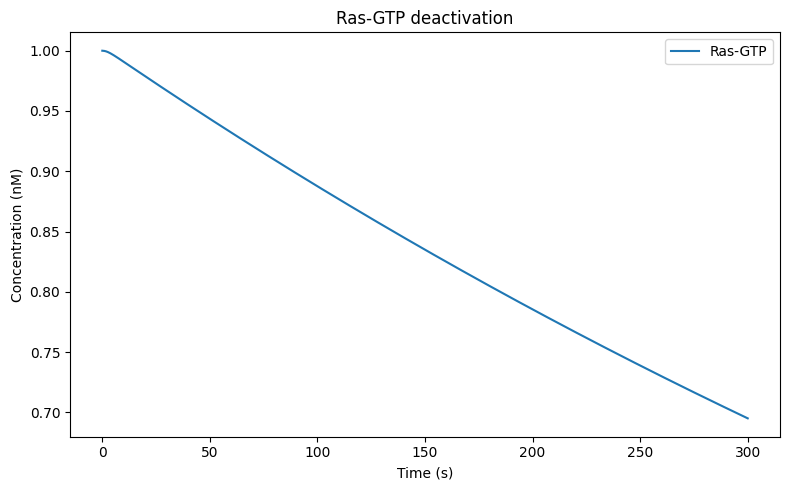

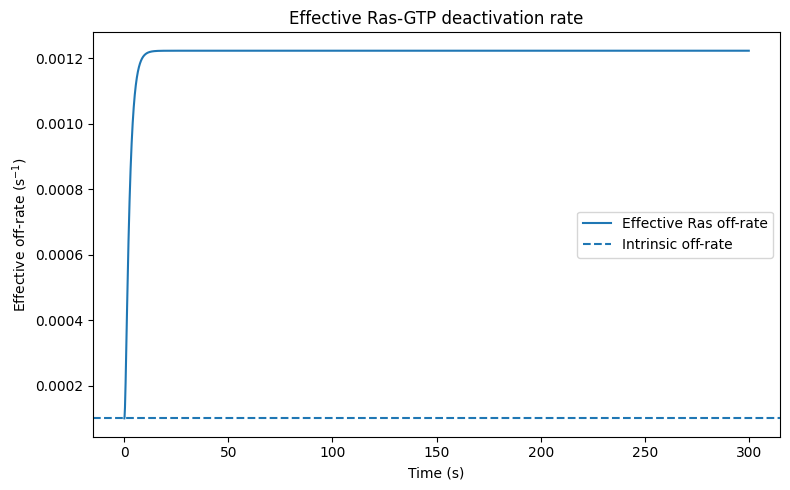

In [42]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt


# ============================================================
# VERSION 1: Kiyatkin-inspired Ras/RasGAP reduced model
#
# Goal:
# Estimate the effective Ras-GTP deactivation rate produced
# by the GAB1/RasGAP branch.
#
# IMPORTANT:
# This is NOT a reconstruction of the entire Kiyatkin model.
# It isolates the RasGAP branch for parameter auditing.
# ============================================================


# ------------------------------------------------------------
# 1. INITIAL CONCENTRATIONS FROM KIYATKIN
# ------------------------------------------------------------

Ras_total = 150.0       # nM
RasGAP_total = 50.0     # nM
GAB1_total = 300.0      # nM


# ------------------------------------------------------------
# 2. CONSTANTS FROM THE KINETIC TABLE
# ------------------------------------------------------------

# Reaction 62a:
# RasT -> RasD
k_Ras_intrinsic = 1e-4      # s^-1


# Reactions 327 / 333 / 338 etc.
#
# GABPp + GAP <-> GABPp-GAP
#
# kon = 8e-6 nM^-1 s^-1
# Kd  = 62500 nM
#
# koff = kon * Kd = 0.5 s^-1

k_GAP_bind = 8e-6           # nM^-1 s^-1
Kd_GAP = 62500.0            # nM
k_GAP_unbind = k_GAP_bind * Kd_GAP   # 0.5 s^-1


# Reactions 371-372:
#
# RasT + GABPp-GAP
#     <-> RasT-GABPp-GAP
#     -> RasD + GABPp-GAP
#
# Reaction 371:
k_Ras_GAP_bind = 0.01       # nM^-1 s^-1

# Reaction 371 Kd:
Kd_Ras_GAP = 10.0           # nM

# Therefore:
k_Ras_GAP_unbind = k_Ras_GAP_bind * Kd_Ras_GAP
# = 0.1 s^-1


# Reaction 372:
k_Ras_GAP_cat = 1.5         # s^-1


# ------------------------------------------------------------
# 3. SHP2 / GAB1 APPROXIMATION
# ------------------------------------------------------------

# The full Kiyatkin model has many GAB1 states.
#
# For Version 1, we represent the amount of GAB1 available
# as phosphorylated GAB1 (GABPp) using an adjustable fraction.
#
# This is NOT a published "50%" value.
# It is an explicit modeling assumption so that we can test
# the RasGAP subsystem before reconstructing the entire GAB1
# state network.

GAB1P_fraction = 0.50

GAB1P_initial = GAB1_total * GAB1P_fraction


# ------------------------------------------------------------
# 4. INITIAL CONDITIONS
# ------------------------------------------------------------

# We begin with 1 nM RasT and the remaining Ras as RasD.
#
# This is a diagnostic initialization, not an experimentally
# measured Kiyatkin initial condition.

RasT0 = 1.0
RasD0 = Ras_total - RasT0

# Start with no RasGAP complexes.
GABPp_GAP0 = 0.0
RasT_GABPp_GAP0 = 0.0

y0 = [
    RasD0,
    RasT0,
    GABPp_GAP0,
    RasT_GABPp_GAP0
]


# ------------------------------------------------------------
# 5. ODE SYSTEM
# ------------------------------------------------------------

def ras_off_model(t, y, GAB1P):

    RasD, RasT, GABPp_GAP, RasT_GABPp_GAP = y

    # --------------------------------------------------------
    # Free RasGAP
    # --------------------------------------------------------

    GAP_free = (
        RasGAP_total
        - GABPp_GAP
        - RasT_GABPp_GAP
    )

    GAP_free = max(GAP_free, 0.0)


    # --------------------------------------------------------
    # Free GAB1P
    # --------------------------------------------------------

    GABPp_free = (
        GAB1P
        - GABPp_GAP
        - RasT_GABPp_GAP
    )

    GABPp_free = max(GABPp_free, 0.0)


    # --------------------------------------------------------
    # GAB1P + GAP <-> GAB1P-GAP
    # --------------------------------------------------------

    v_GAP_bind = (
        k_GAP_bind
        * GABPp_free
        * GAP_free
    )

    v_GAP_unbind = (
        k_GAP_unbind
        * GABPp_GAP
    )


    # --------------------------------------------------------
    # RasT + GAB1P-GAP <-> RasT-GAB1P-GAP
    # --------------------------------------------------------

    v_Ras_bind = (
        k_Ras_GAP_bind
        * RasT
        * GABPp_GAP
    )

    v_Ras_unbind = (
        k_Ras_GAP_unbind
        * RasT_GABPp_GAP
    )


    # --------------------------------------------------------
    # Catalytic RasT -> RasD
    # --------------------------------------------------------

    v_Ras_GAP_cat = (
        k_Ras_GAP_cat
        * RasT_GABPp_GAP
    )


    # --------------------------------------------------------
    # Intrinsic RasT -> RasD
    # --------------------------------------------------------

    v_intrinsic = (
        k_Ras_intrinsic
        * RasT
    )


    # --------------------------------------------------------
    # ODEs
    # --------------------------------------------------------

    dRasD = (
        v_intrinsic
        + v_Ras_GAP_cat
    )

    dRasT = (
        -v_intrinsic
        -v_Ras_GAP_cat
    )

    dGABPp_GAP = (
        v_GAP_bind
        -v_GAP_unbind
        -v_Ras_bind
        +v_Ras_unbind
        +v_Ras_GAP_cat
    )

    dRasT_GABPp_GAP = (
        v_Ras_bind
        -v_Ras_unbind
        -v_Ras_GAP_cat
    )

    return [
        dRasD,
        dRasT,
        dGABPp_GAP,
        dRasT_GABPp_GAP
    ]


# ------------------------------------------------------------
# 6. RUN MODEL
# ------------------------------------------------------------

t_eval = np.linspace(0, 300, 3000)

solution = solve_ivp(
    ras_off_model,
    [0, 300],
    y0,
    args=(GAB1P_initial,),
    method="BDF",
    t_eval=t_eval,
    rtol=1e-9,
    atol=1e-12
)


# ------------------------------------------------------------
# 7. EXTRACT RESULTS
# ------------------------------------------------------------

RasD = solution.y[0]
RasT = solution.y[1]
GABPp_GAP = solution.y[2]
RasT_GABPp_GAP = solution.y[3]


# ------------------------------------------------------------
# 8. EFFECTIVE RAS OFF-RATE
# ------------------------------------------------------------

# Definition:
#
# k_off_eff =
#
#   total RasT deactivation flux
#   --------------------------------
#             RasT
#
# Here the total flux is:
#
# intrinsic RasT loss
# +
# RasGAP-catalyzed RasT loss

intrinsic_flux = k_Ras_intrinsic * RasT

GAP_flux = k_Ras_GAP_cat * RasT_GABPp_GAP

total_Ras_off_flux = intrinsic_flux + GAP_flux


k_Ras_off_eff = np.where(
    RasT > 1e-12,
    total_Ras_off_flux / RasT,
    np.nan
)


# ------------------------------------------------------------
# 9. DIAGNOSTICS
# ------------------------------------------------------------

print("Solver success:", solution.success)
print("Message:", solution.message)

print()
print("Initial Ras total:",
      RasD0 + RasT0)

print("Final Ras total:",
      RasD[-1] + RasT[-1])

print("Ras total error:",
      abs((RasD[-1] + RasT[-1]) - Ras_total))

print()
print("GAB1P initial:", GAB1P_initial)
print("Final GABPp-GAP:", GABPp_GAP[-1])
print("Final RasT-GABPp-GAP:",
      RasT_GABPp_GAP[-1])

print()
print("Initial effective Ras off-rate:",
      k_Ras_off_eff[0],
      "s^-1")

print("Final effective Ras off-rate:",
      k_Ras_off_eff[-1],
      "s^-1")

print("Maximum effective Ras off-rate:",
      np.nanmax(k_Ras_off_eff),
      "s^-1")


# ------------------------------------------------------------
# 10. PLOT RAST
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    solution.t,
    RasT,
    label="Ras-GTP"
)

plt.xlabel("Time (s)")
plt.ylabel("Concentration (nM)")
plt.title("Ras-GTP deactivation")

plt.legend()
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 11. PLOT EFFECTIVE OFF-RATE
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    solution.t,
    k_Ras_off_eff,
    label="Effective Ras off-rate"
)

plt.axhline(
    k_Ras_intrinsic,
    linestyle="--",
    label="Intrinsic off-rate"
)

plt.xlabel("Time (s)")
plt.ylabel("Effective off-rate (s$^{-1}$)")
plt.title("Effective Ras-GTP deactivation rate")

plt.legend()
plt.tight_layout()
plt.show()

In [43]:
fractions = [0.10, 0.25, 0.50, 0.75, 1.00]

results = []

for fraction in fractions:

    GAB1P = GAB1_total * fraction

    sol = solve_ivp(
        ras_off_model,
        [0, 300],
        y0,
        args=(GAB1P,),
        method="BDF",
        t_eval=t_eval,
        rtol=1e-9,
        atol=1e-12
    )

    RasT_test = sol.y[1]
    complex_test = sol.y[3]

    intrinsic_flux = k_Ras_intrinsic * RasT_test
    GAP_flux = k_Ras_GAP_cat * complex_test

    k_eff = (
        intrinsic_flux + GAP_flux
    ) / RasT_test

    results.append({
        "GAB1P_fraction": fraction,
        "GAB1P_nM": GAB1P,
        "k_eff_final": k_eff[-1],
        "fold_vs_intrinsic": k_eff[-1] / k_Ras_intrinsic
    })


for result in results:
    print(
        f"GAB1P = {result['GAB1P_nM']:.1f} nM | "
        f"k_eff = {result['k_eff_final']:.6g} s^-1 | "
        f"{result['fold_vs_intrinsic']:.2f}x intrinsic"
    )

GAB1P = 30.0 nM | k_eff = 0.000324757 s^-1 | 3.25x intrinsic
GAB1P = 75.0 nM | k_eff = 0.000661608 s^-1 | 6.62x intrinsic
GAB1P = 150.0 nM | k_eff = 0.00122227 s^-1 | 12.22x intrinsic
GAB1P = 225.0 nM | k_eff = 0.00178198 s^-1 | 17.82x intrinsic
GAB1P = 300.0 nM | k_eff = 0.00234075 s^-1 | 23.41x intrinsic
